# Stage 2.5 — smaller models, resumable pilot, measured costs

This notebook runs **only the authorized single-seed C pilot**, with 12 pruning rounds (13 stages) at 10,000 updates, plus 500/1,000-update timing probes. It does **not** launch Stage 3 or a three-seed sweep. All outputs are saved under `reports/stage2_5/`.

New A/B/C widths are 162–421, 200–204, and 231–77. `LeNet300100`, `legacy_A`, and `legacy_B` retain the old networks. Stage 1/2 configurations explicitly use the legacy reference, and their recorded results are untouched.

The full 55,000/5,000/10,000 MNIST split, seed 42, batch 60, Adam 0.0012, Glorot normal and validated pruning/reset rules are unchanged. The test set is not evaluated. Primary validation is every **500** updates; fine diagnostic evaluations every **100** updates are recorded but never select primary results or stop training. Final trained weights always determine the next mask.

CPU uses one thread and exactly equivalent precomputed float32 pixels to avoid repeated PIL conversion. Pixel equivalence and deterministic stage-boundary resume are tested. This changes execution cost, not the dataset or preprocessing values. Bitwise cross-platform equality is not promised.

In [1]:
from pathlib import Path
import subprocess, sys, json
import pandas as pd
import yaml
from IPython.display import display, Image
from stage2_5_analysis import (REPORT, architecture_table, run_benchmarks, run_pilot,
    convergence_and_sampling, cost_projections, save_figures)
REPORT.mkdir(parents=True, exist_ok=True)
tests = subprocess.run([sys.executable, "-m", "pytest", "-q"], capture_output=True, text=True)
(REPORT / "tests.txt").write_text(tests.stdout + tests.stderr)
print(tests.stdout)
tests.check_returncode()
counts = architecture_table()
assert counts.parameters.tolist() == [200013, 200054, 199979, 266610]
counts.to_csv(REPORT / "parameter_counts.csv", index=False)
display(counts)

.................................................                        [100%]
49 passed in 6.41s



,architecture,hidden1,hidden2,parameters
0,A,162,421,200013
1,B,200,204,200054
2,C,231,77,199979
3,LeNet300100,300,100,266610


## Timing and pruning probes

New networks run 500 and 1,000 updates per stage, dense + one pruning round. Legacy networks run short dense-plus-one-round probes with the same optimized pipeline and validation grid, so the effect of model size is not confused with pipeline changes. Historical Stage 2 timings are reported separately. CPU/GPU timings are never extrapolated from one device to another.

In [2]:
# Reuse completed benchmark evidence on notebook restart.
if (REPORT / "benchmarks.csv").exists():
    benchmarks = pd.read_csv(REPORT / "benchmarks.csv")
    assert len(benchmarks) == 24, "Incomplete benchmark table: rerun run_benchmarks() explicitly"
else:
    benchmarks = run_benchmarks()
display(benchmarks[["architecture", "stage", "iterations", "parameters", "remaining_percent", "runtime_seconds"]])

,architecture,stage,iterations,parameters,remaining_percent,runtime_seconds
0,A,0,500,200013,100.000000,1.547884
1,A,1,500,200013,80.211614,2.267491
2,A,0,1000,200013,100.000000,3.150738
3,A,1,1000,200013,80.211614,4.649723
4,B,0,500,200054,100.000000,1.570618
5,B,1,500,200054,80.102184,2.476635
6,B,0,1000,200054,100.000000,3.644393
7,B,1,1000,200054,80.102184,5.384381
8,C,0,500,199979,100.000000,2.057223
9,C,1,500,199979,80.039166,3.604497


## C (231–77), seed 0: all 12 pruning rounds

Each completed stage atomically commits its final ticket weights, masks, history, result rows and checksums. Initial weights, the split and scientific configuration are preserved. On interruption the next execution resumes from the latest committed stage and reruns only an incomplete stage. Resumption is between stages; Adam is intentionally fresh at every new stage. Do not run two writers against the same run directory.

Only compatible new-format checkpoints can resume; old Stage 1/2 outputs are never migrated or overwritten. Equivalent software, code, CPU thread count, model widths and split are required. To resume from a terminal: `python experiment.py --resume PATH_TO_RUN`.

In [3]:
config = yaml.safe_load(Path("config_stage2_5.yaml").read_text())
display(config)
run_dir, results = run_pilot(config)
assert len(results) == 13 and results.stage.tolist() == list(range(13))
assert results.iterations.eq(10000).all()
print("Pilot:", run_dir.resolve())
display(results[["stage", "remaining_percent", "best_iteration", "best_validation_loss", "best_validation_accuracy", "runtime_seconds"]])

{'architecture': 'C',
 'seed': 0,
 'rounds': 12,
 'iterations': 10000,
 'eval_interval': 500,
 'trace_interval': 100,
 'split_seed': 42,
 'learning_rate': 0.0012,
 'control': False,
 'device': 'cpu',
 'num_threads': 1,
 'preload_tensors': True,
 'data_dir': 'datasets',
 'download': False,
 'output_dir': 'reports/stage2_5/pilot',
 'progress': True}

Pilot: /workspace/Advanced-topics-in-Deep-learning/reports/stage2_5/pilot/C-seed0-msu2cpkt


,stage,remaining_percent,best_iteration,best_validation_loss,best_validation_accuracy,runtime_seconds
0,0,100.000000,2500,0.077177,0.9746,43.856466
1,1,80.039166,2500,0.074960,0.9772,56.966002
2,2,64.066593,2500,0.070981,0.9786,68.397497
3,3,51.285429,2500,0.065032,0.9814,64.709850
4,4,41.057092,2500,0.063511,0.9812,66.611664
5,5,32.871718,2500,0.063510,0.9820,79.694485
6,6,26.320613,2500,0.062384,0.9790,66.647643
7,7,21.077727,2500,0.062638,0.9796,64.078245
8,8,16.881113,2500,0.063928,0.9796,62.272959
9,9,13.521920,2500,0.065971,0.9782,62.347759


,stage,remaining_weights,remaining_parameters,remaining_percent,best_iteration_100,best_iteration_500,loss_100,loss_500,accuracy_100,accuracy_500,coarse_minus_fine_loss,coarse_minus_fine_accuracy_pp,best_in_last_20pct_500,best_at_final_500,loss_improvement_in_last_20pct,final_loss,final_accuracy,primary_runtime_seconds,diagnostic_evaluation_seconds
0,0,199661,199979,100.000000,4100,2500,0.075085,0.077177,0.9802,0.9746,0.002093,-0.56,False,False,-0.007294,0.100409,0.9786,39.120754,4.735713
1,1,159807,160125,80.039166,2600,2500,0.074508,0.074960,0.9782,0.9772,0.000452,-0.10,False,False,-0.013223,0.114604,0.9754,52.072001,4.894001
2,2,127916,128234,64.066593,2600,2500,0.070505,0.070981,0.9792,0.9786,0.000475,-0.06,False,False,-0.012092,0.108570,0.9802,63.457577,4.939919
3,3,102397,102715,51.285429,2500,2500,0.065032,0.065032,0.9814,0.9814,0.000000,0.00,False,False,-0.032828,0.104213,0.9802,60.128468,4.581382
4,4,81975,82293,41.057092,2500,2500,0.063511,0.063511,0.9812,0.9812,0.000000,0.00,False,False,-0.025651,0.111437,0.9814,61.552645,5.059019
5,5,65632,65950,32.871718,2500,2500,0.063510,0.063510,0.9820,0.9820,0.000000,0.00,False,False,-0.028047,0.095054,0.9796,73.348550,6.345935
6,6,52552,52870,26.320613,2500,2500,0.062384,0.062384,0.9790,0.9790,0.000000,0.00,False,False,-0.033817,0.105498,0.9798,61.289514,5.358128
7,7,42084,42402,21.077727,2500,2500,0.062638,0.062638,0.9796,0.9796,0.000000,0.00,False,False,-0.021323,0.109352,0.9784,58.849462,5.228783
8,8,33705,34023,16.881113,2500,2500,0.063928,0.063928,0.9796,0.9796,0.000000,0.00,False,False,-0.023141,0.095862,0.9790,56.989920,5.283039
9,9,26998,27316,13.521920,2500,2500,0.065971,0.065971,0.9782,0.9782,0.000000,0.00,False,False,-0.028109,0.112708,0.9774,56.740068,5.607691


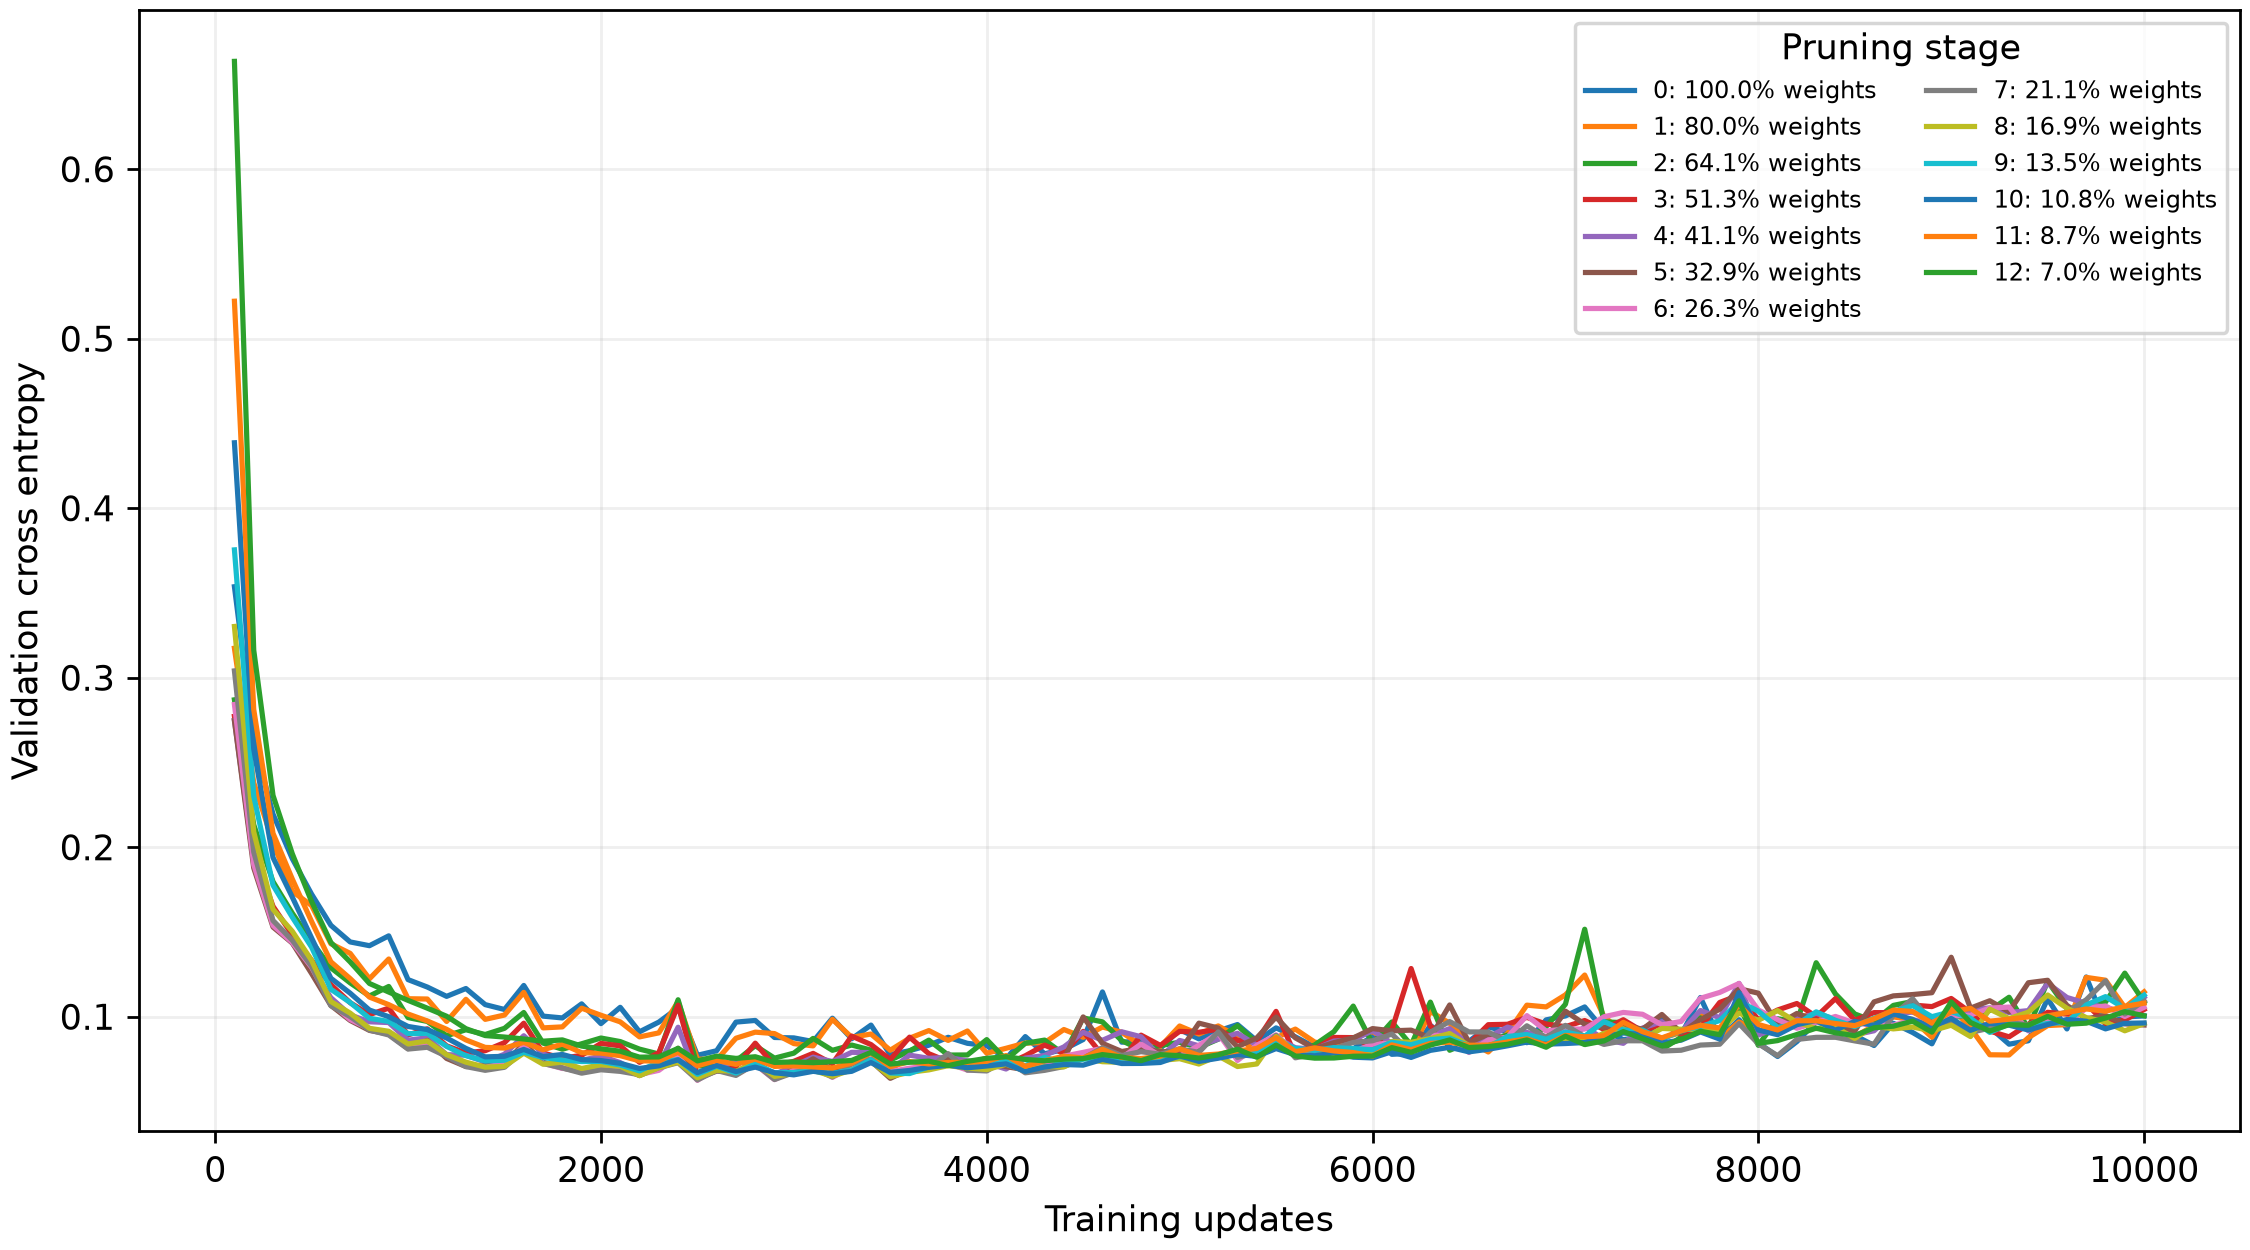

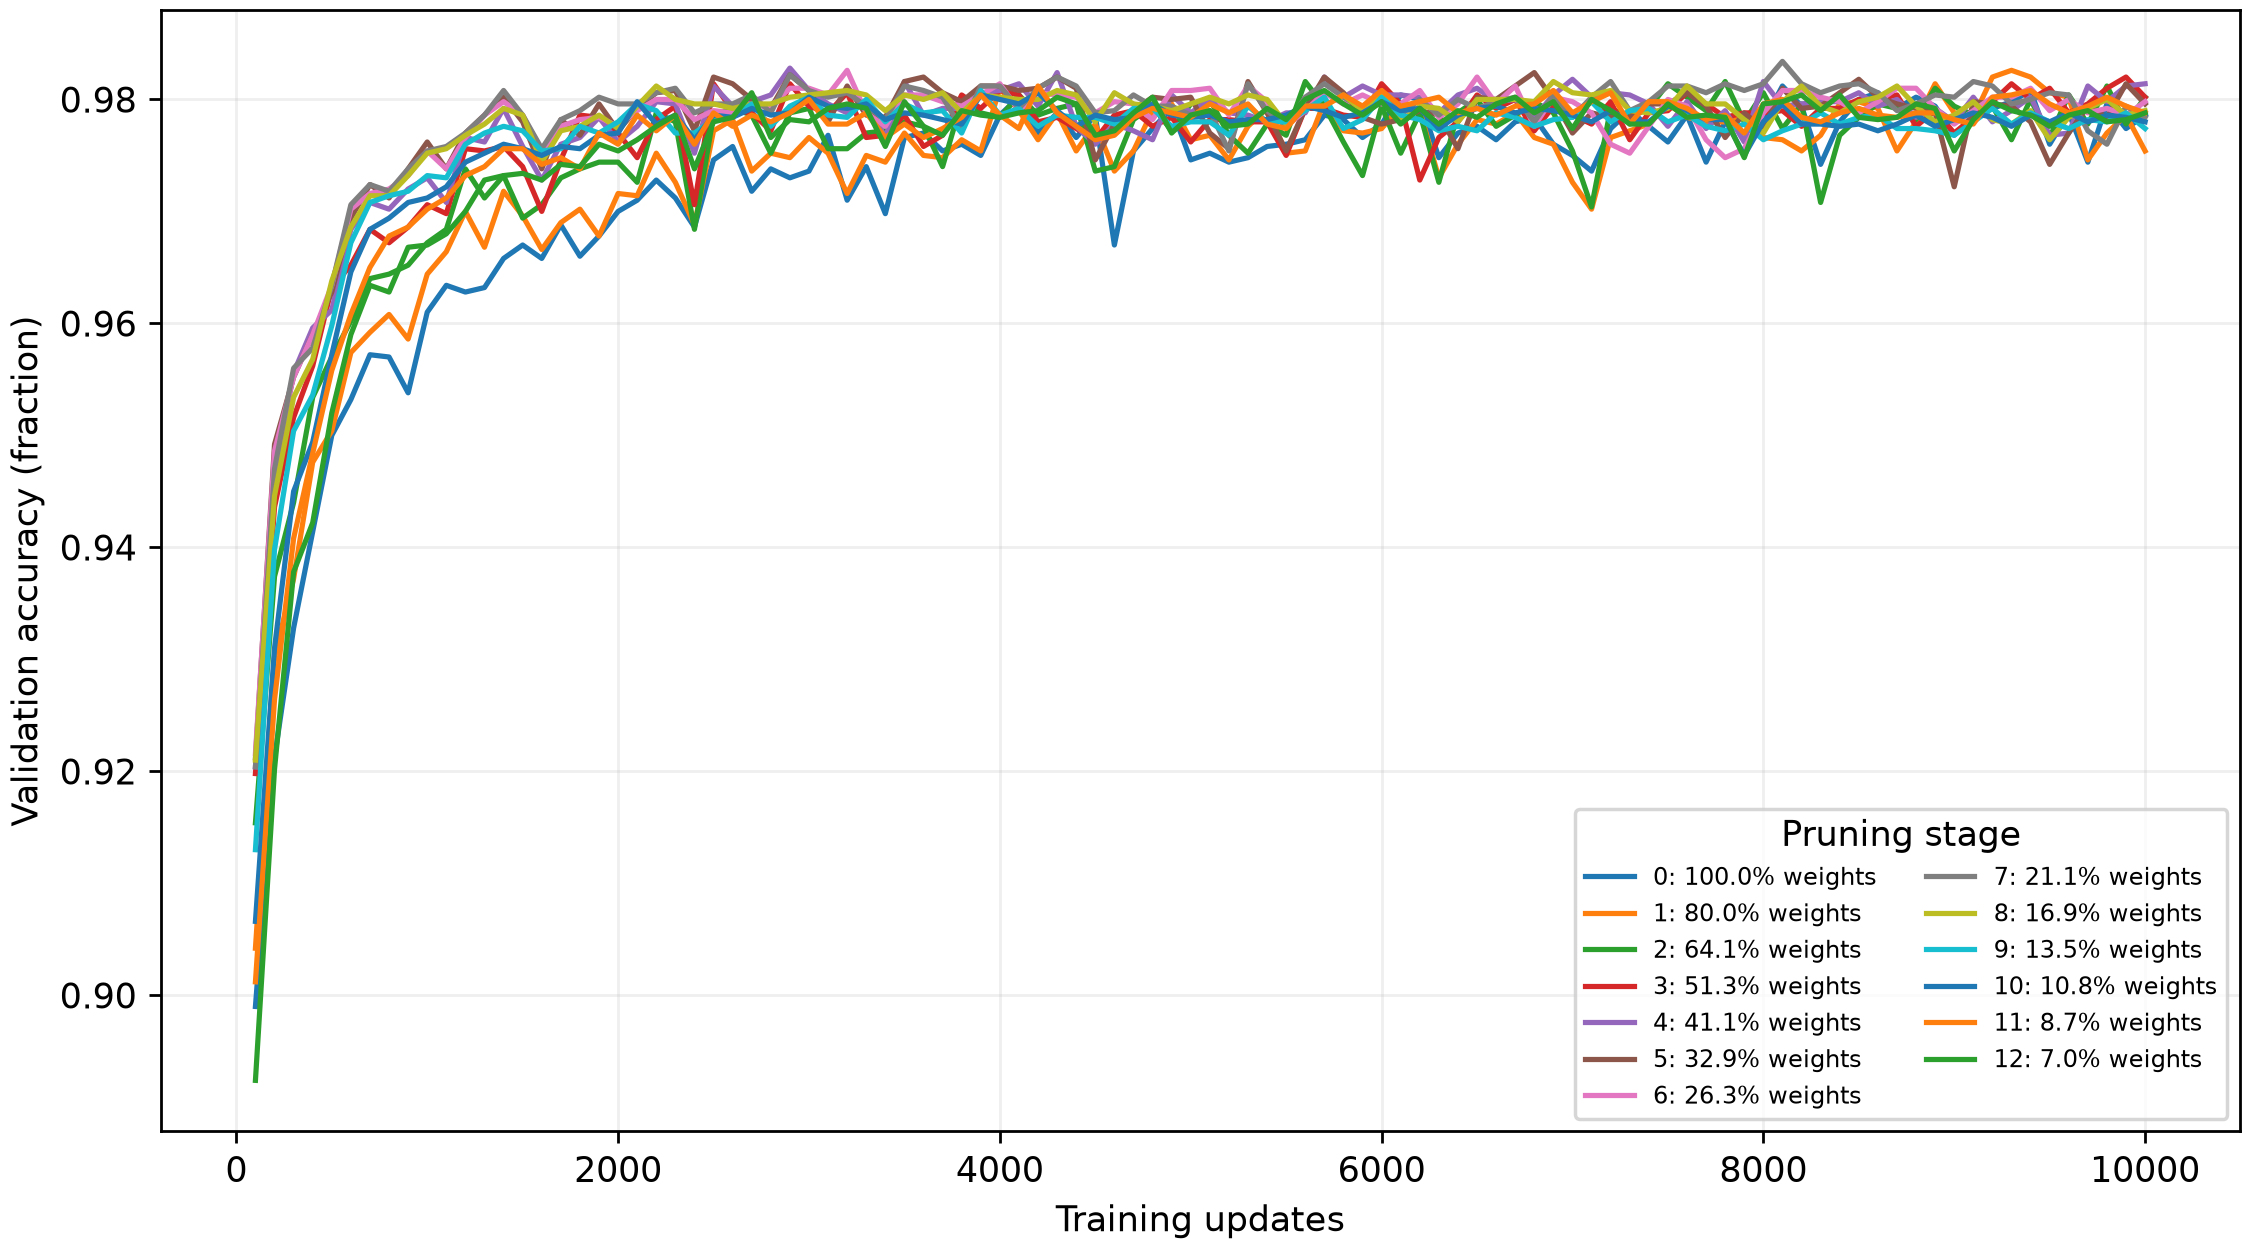

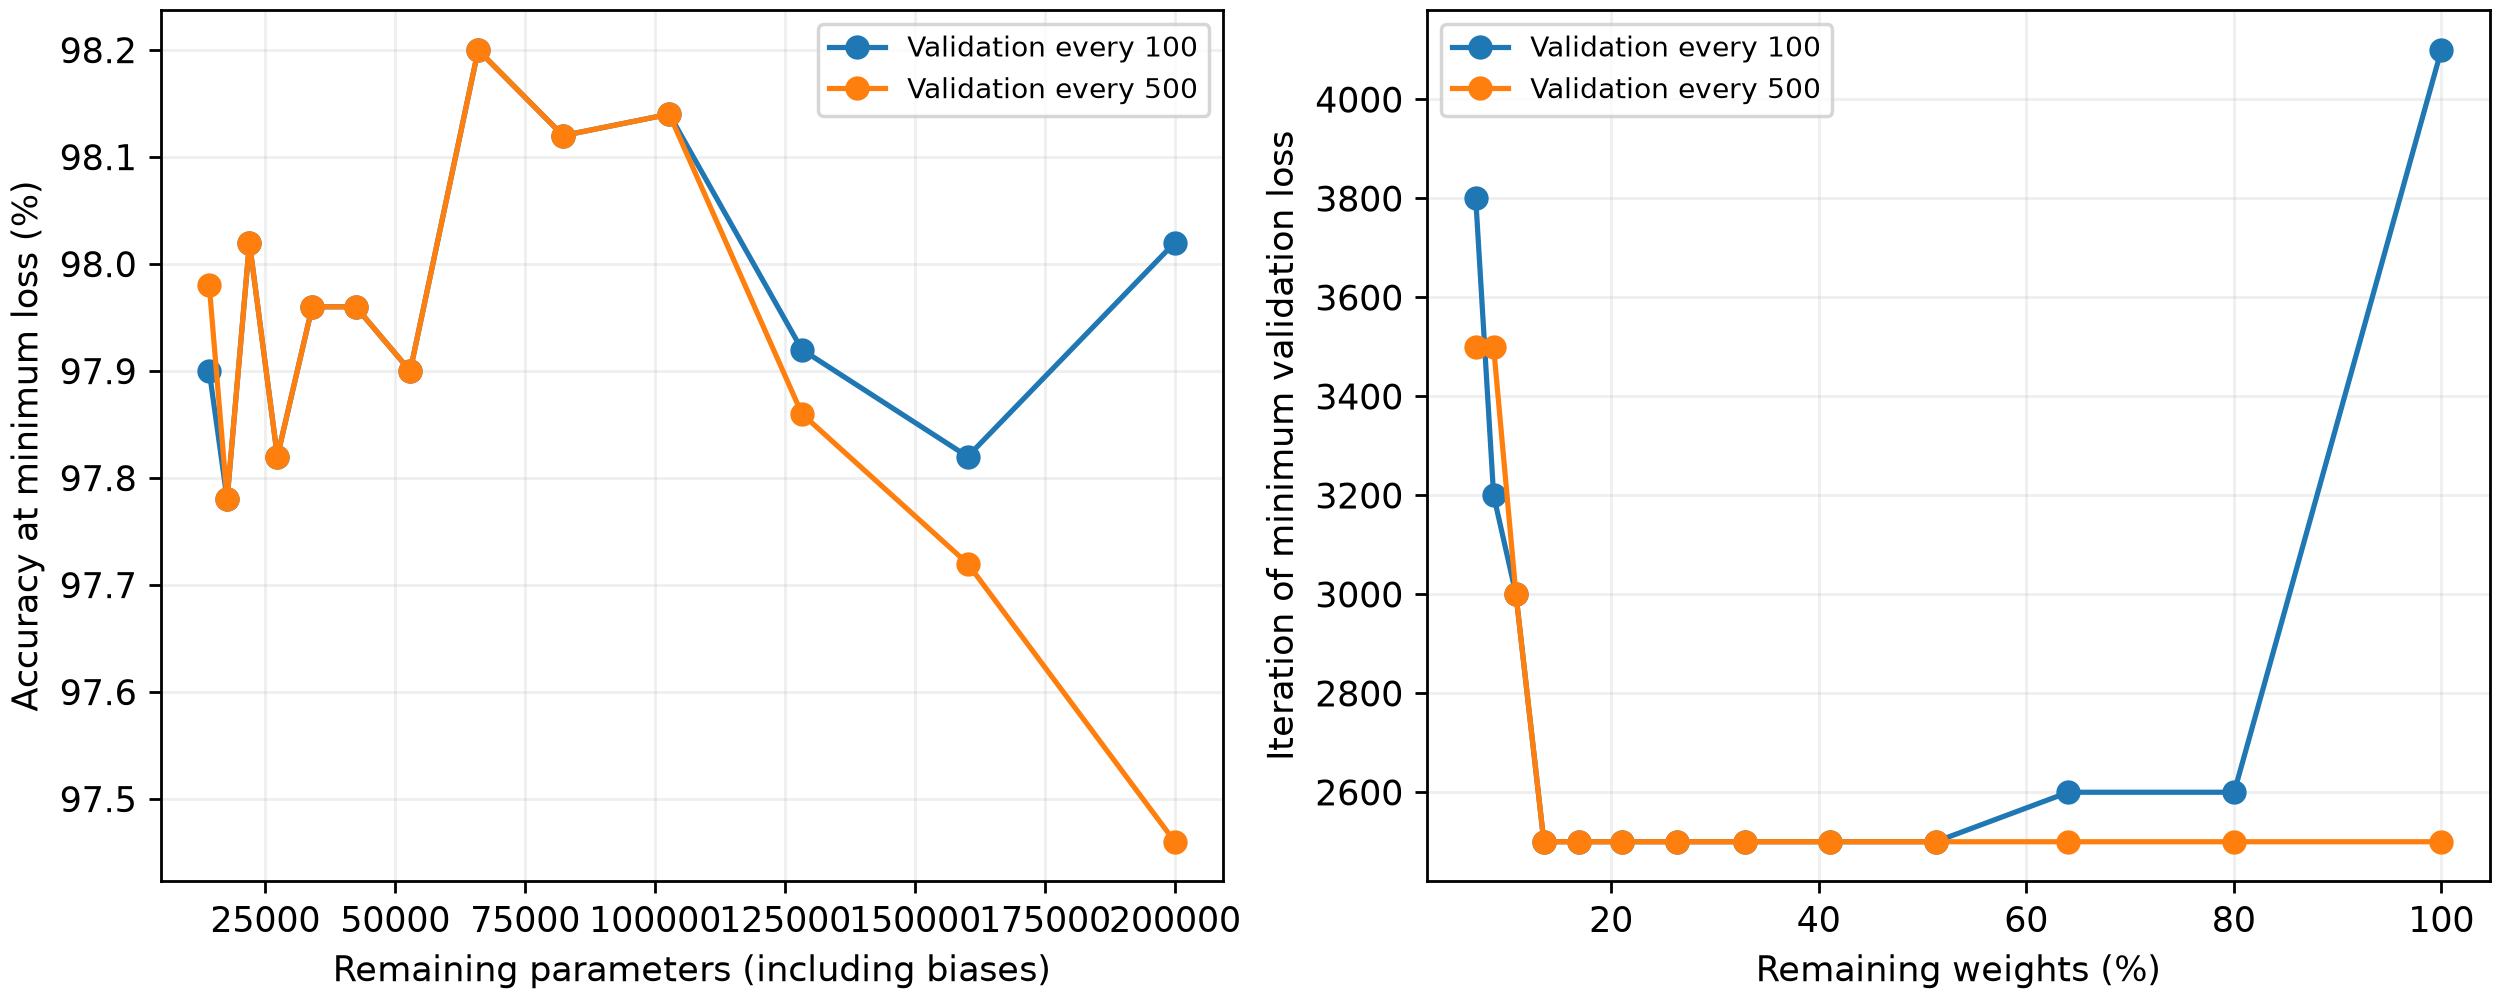

Primary minima in last 20%: 0 / 13
Primary minima at final update: 0 / 13
Max |accuracy selection difference|, pp: 0.5599999999999938


In [4]:
diagnostics, history = convergence_and_sampling(run_dir)
save_figures(diagnostics, history)
display(diagnostics)
for name in ("validation_loss", "validation_accuracy", "accuracy_trainability"):
    display(Image(filename=str(REPORT / f"{name}.png")))
print("Primary minima in last 20%:", int(diagnostics.best_in_last_20pct_500.sum()), "/ 13")
print("Primary minima at final update:", int(diagnostics.best_at_final_500.sum()), "/ 13")
print("Max |accuracy selection difference|, pp:", diagnostics.coarse_minus_fine_accuracy_pp.abs().max())

In [5]:
costs = cost_projections(results, benchmarks)
display(costs)
print((REPORT / "hardware.json").read_text())

,setup,device,architectures,seeds,stages,iterations,total_updates,estimated_hours,planning_hours_plus_25_percent
0,200k eval500 optimized pipeline,cpu,3,3,13,10000,1170000,1.538155,1.922694
1,266k eval500 matched optimized pipeline,cpu,3,3,13,10000,1170000,1.509001,1.886251
2,266k previous Stage 2 eval100 pipeline,cpu,3,3,13,10000,1170000,3.869237,4.836546
3,200k eval500 matched short-probe projection,cpu,3,3,13,10000,1170000,1.466171,1.832714
4,200k eval100 sensitivity estimate,cpu,3,3,13,10000,1170000,1.693539,2.116924


{
  "torch": "2.6.0+cpu",
  "cuda_available": false,
  "mps_available": false,
  "cpu_threads": 1,
  "gpu_timings": "Unavailable; no GPU measured"
}


,setup,device,architectures,seeds,stages,iterations,total_updates,estimated_hours,planning_hours_plus_25_percent
0,200k eval500 optimized pipeline,cpu,3,3,13,10000,1170000,1.538155,1.922694
1,266k eval500 matched optimized pipeline,cpu,3,3,13,10000,1170000,1.509001,1.886251
2,266k previous Stage 2 eval100 pipeline,cpu,3,3,13,10000,1170000,3.869237,4.836546
3,200k eval500 matched short-probe projection,cpu,3,3,13,10000,1170000,1.466171,1.832714
4,200k eval100 sensitivity estimate,cpu,3,3,13,10000,1170000,1.693539,2.116924


# Stage 2.5 assessment

**C — run additional targeted A/B pilots before deciding.** 10,000 updates looks promising for this C seed, but is not established for A/B. Propose A and B, seed 0 only, 12 pruning rounds at 10,000 updates and validation every 100, downsampling the same traces to 500 for comparison. The 500-grid change is not yet scientifically neutral. These are two single-seed pilots, not the three-seed study. Extend flagged high-sparsity stages to 15k/20k in separate fixed-mask diagnostic probes if minima remain late.

No Stage 3/full three-seed experiment has been started. The completed scientific pilot is C (231–77), seed 0, 12 pruning rounds / 13 training stages, 10,000 fixed updates per stage. All 55,000/5,000/10,000 MNIST examples are retained; the test set was not evaluated.

**Sampling-frequency caution:** The dense 100-grid selection is 98.02% at update 4,100; the 500-grid selection is 97.46% at update 2,500. That is a **0.56 percentage-point** difference and **1,600 updates** in the reported trainability statistic. At stage 12, the ticket-minus-dense accuracy is +0.52 pp on the 500 grid but -0.12 pp on the 100 grid. The coarser grid therefore changes even the sign of this descriptive single-seed comparison. This does not establish a population-level advantage, but it shows that 500-step evaluation cannot be assumed harmless for this research question. Keep the requested code default of 500; recommend retaining every-100 evaluation for scientific comparisons unless the follow-up establishes grid robustness.

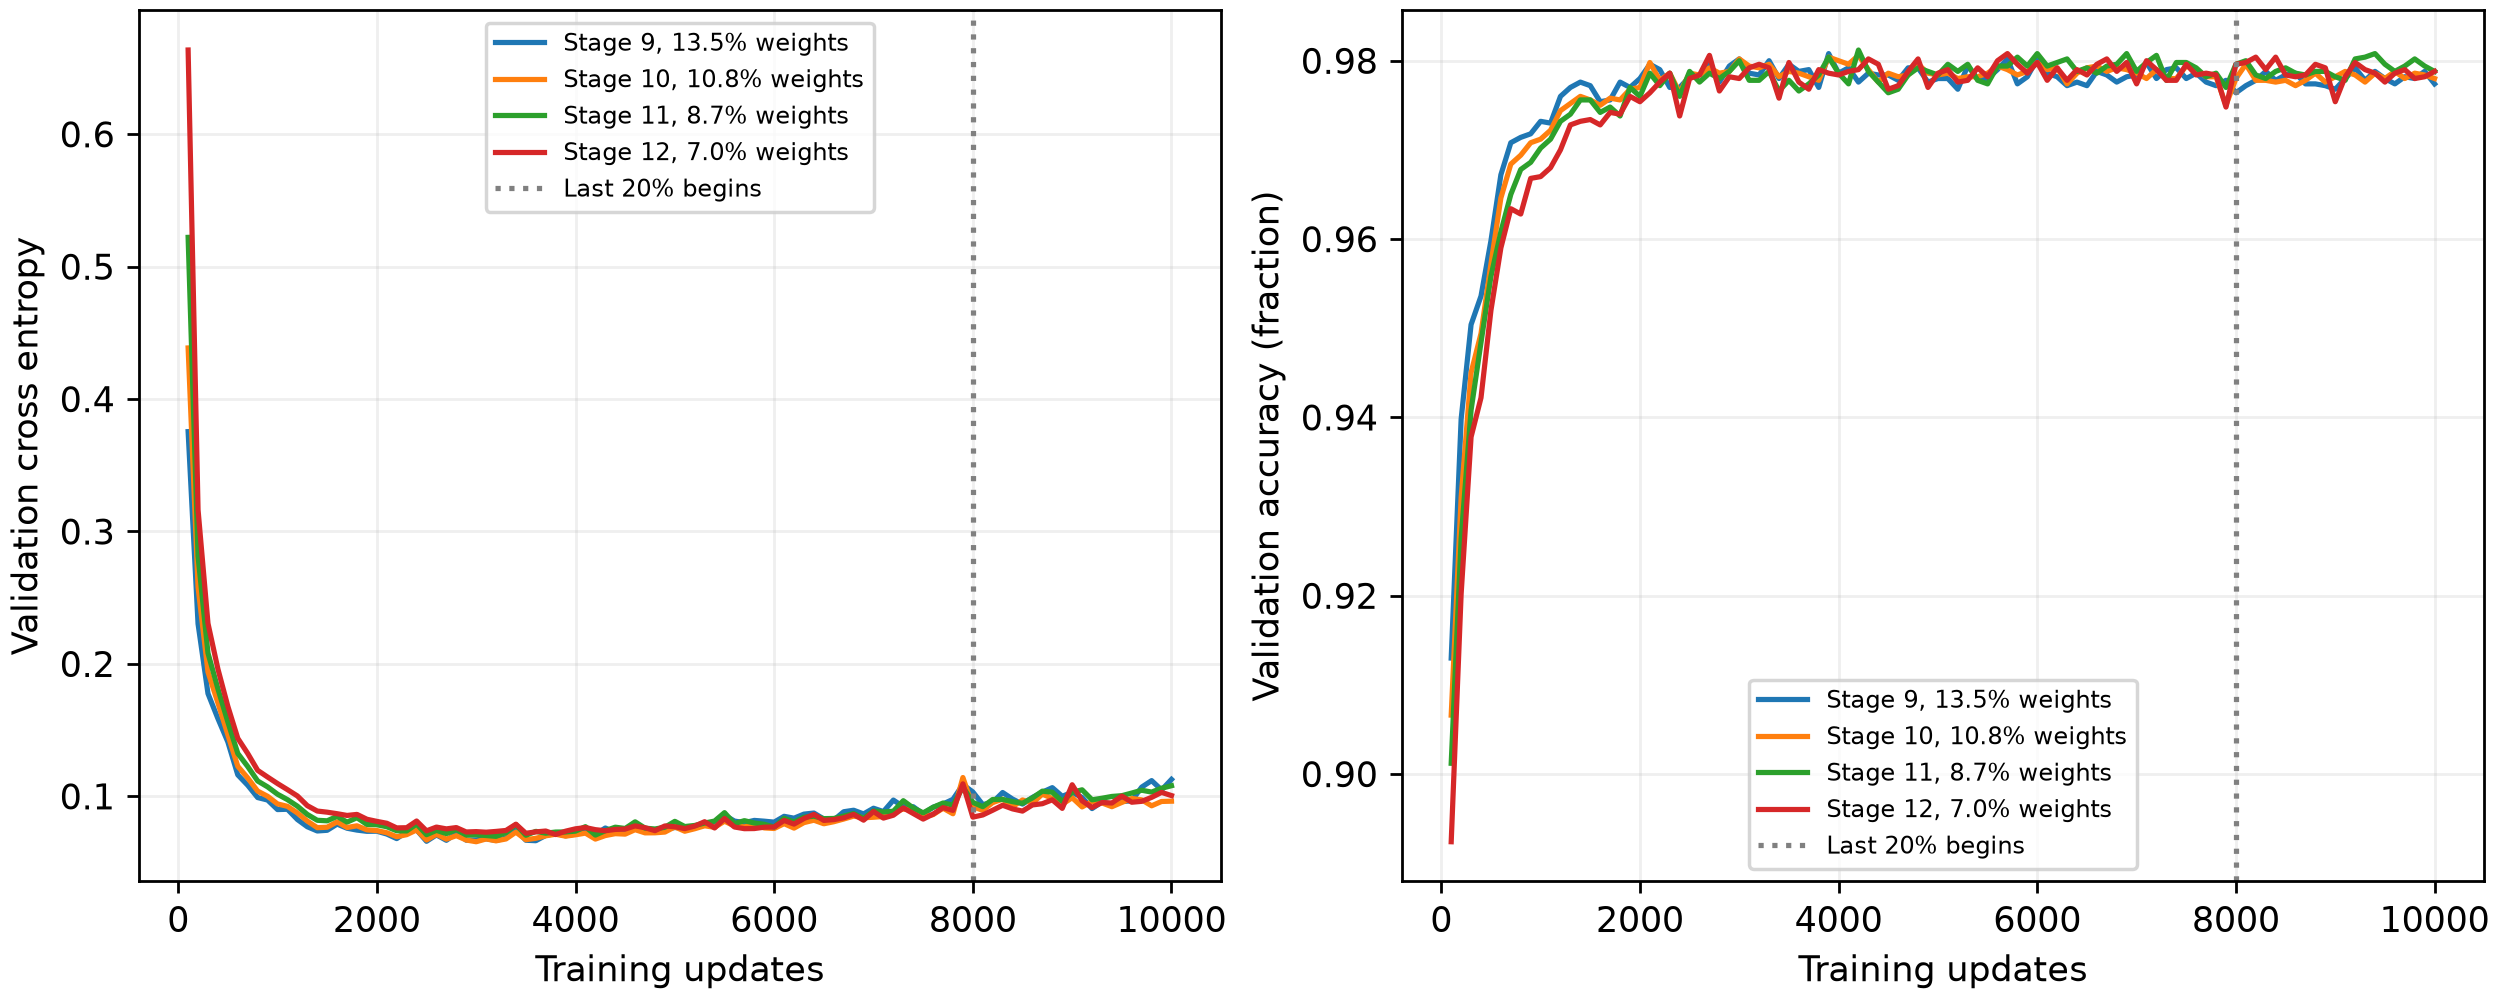

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
from stage2_5_analysis import (REPORT, complete_legacy_pruning_benchmarks, cost_projections,
    save_high_sparsity_figures, write_assessment)
benchmarks = complete_legacy_pruning_benchmarks(pd.read_csv(REPORT / "benchmarks.csv"))
results = pd.read_csv(REPORT / "results.csv")
diagnostics = pd.read_csv(REPORT / "convergence_sampling.csv")
history = pd.read_csv(REPORT / "validation_history.csv")
costs = cost_projections(results, benchmarks)
save_high_sparsity_figures(history)
assessment = write_assessment(diagnostics, costs, results)
display(costs)
display(Markdown("\n\n".join(assessment.split("\n\n")[:3])))
for paragraph in assessment.split("\n\n"):
    if paragraph.startswith("**Sampling-frequency caution:"):
        display(Markdown(paragraph))
display(Image(filename=str(REPORT / "high_sparsity_learning.png")))


## Interpretation and next decision

The 100-versus-500 comparison uses the **same recorded weights and training trajectory**; it measures selection-grid effects rather than different training runs. Best iterations are quantized to their validation grid. Diagnostic-only validation time is measured separately and subtracted in primary-grid CPU projections. This subtraction is approximate; the short benchmarks directly use every-500 validation.

Treat minima near the last 20% of the budget (8,000–10,000), especially repeated final-update minima and continued late loss decreases at high sparsity, as evidence that the budget may be too short. Earlier minima alone cannot prove convergence. One C seed cannot establish adequacy for A/B or statistical significance of accuracy differences.

The recommended decision is written with the observed results in `reports/stage2_5/assessment.md`. No full experiment is started. A 10,000-update/every-500 study is an explicit deviation from G.1's 50,000/every-100 protocol; keep the training budget fixed rather than stopping on validation.